# 📊 01. Exploratory Data Analysis & Operational Dynamics
### PreZero / Fillinq Challenge: AI-Driven Smart Waste Routing
**City of Heilbronn Municipal Glass Recycling Optimization**

> **Operational Ground Truth:** In this dataset, **every recorded reading corresponds to a truck collection visit**. When a collection truck visits a container location, the driver/sensor records the observed fill level (`fill_level_perc`), and the container is immediately emptied to $0\%$. Therefore:
> * The days elapsed between consecutive recorded visits ($\Delta t = t_i - t_{i-1}$) is the **actual collection turnaround cadence**.
> * The daily accumulation velocity is: $$v_i = \frac{\text{Fill Level}_i}{\Delta t_i} \quad (\%/\text{day})$$
> * The time required for a container to reach $100\%$ full capacity is: $$T_{\text{full}} = \frac{100\%}{v_i} = \frac{100 \times \Delta t_i}{\text{Fill Level}_i} \quad (\text{days})$$


In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.data_loader import load_and_clean_data

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['figure.dpi'] = 110
MAT_COLORS = {'white': '#1f77b4', 'green': '#2ca02c', 'brown': '#8c564b', 'White': '#1f77b4', 'Green': '#2ca02c', 'Brown': '#8c564b'}

print("Environment ready for Exploratory Data Analysis.")


Environment ready for Exploratory Data Analysis.


---
## 📥 1. Data Ingestion & Sanitization
Load the 11,701 collection records, clean column headers, parse dates, map overfull readings ($110\%$), and integrate Baden-Württemberg holiday periods.


In [2]:
df = load_and_clean_data("glass_fill_levels_anonymized_f.csv")
print(f"Dataset successfully loaded: {len(df):,} total collection events across {df['Location_id'].nunique()} unique locations.")
print(f"Observation window: {df['date'].min().date()} to {df['date'].max().date()} (348 calendar days).")
display(df.head(6))


Dataset successfully loaded: 11,701 total collection events across 449 unique locations.
Observation window: 2025-10-17 to 2026-09-30 (348 calendar days).


,Location_id,material_type,date,fill_level_perc,is_overfull,fill_num,year_month,day_name,day_of_week,week_number,is_holiday,holiday_name,prev_date,prev_fill,days_diff,fill_diff
0,0004c095-29ec-4894-81a8-05f3a7a55650,brown,2025-10-31,100,False,100.0,2025-10,Friday,4,44,True,Pre-Allerheiligen (-1d),NaT,NaN,NaN,NaN
1,0004c095-29ec-4894-81a8-05f3a7a55650,brown,2025-12-08,40,False,40.0,2025-12,Monday,0,50,False,Standard Regular Day,2025-10-31,100.0,38.0,-60.0
2,0004c095-29ec-4894-81a8-05f3a7a55650,brown,2025-12-23,80,False,80.0,2025-12,Tuesday,1,52,True,Christmas / New Year Season,2025-12-08,40.0,15.0,40.0
3,0004c095-29ec-4894-81a8-05f3a7a55650,brown,2026-02-25,60,False,60.0,2026-02,Wednesday,2,9,False,Standard Regular Day,2025-12-23,80.0,64.0,-20.0
4,0004c095-29ec-4894-81a8-05f3a7a55650,brown,2026-04-14,100,False,100.0,2026-04,Tuesday,1,16,False,Standard Regular Day,2026-02-25,60.0,48.0,40.0
5,0004c095-29ec-4894-81a8-05f3a7a55650,brown,2026-05-18,100,False,100.0,2026-05,Monday,0,21,False,Standard Regular Day,2026-04-14,100.0,34.0,0.0


---
## 📈 2. Dataset Health Check & Core KPIs


In [3]:
n_records = len(df)
n_locations = df['Location_id'].nunique()
n_dates = df['date'].nunique()
span_days = (df['date'].max() - df['date'].min()).days
n_overfull = df['is_overfull'].sum()

summary_df = pd.DataFrame({
    'Metric': [
        'Total Recorded Collection Visits',
        'Unique Container Locations',
        'Distinct Observation Dates',
        'Date Span Start',
        'Date Span End',
        'Total Duration (Days)',
        'Average Collection Visits per Location',
        'Total Overfull Events Captured',
        'Global Overfull Rate (%)',
        'Visits in Holiday & Festive Surge Windows'
    ],
    'Value': [
        f"{n_records:,}",
        f"{n_locations}",
        f"{n_dates}",
        f"{df['date'].min().date()}",
        f"{df['date'].max().date()}",
        f"{span_days} days (~{span_days/30.4:.1f} months)",
        f"{n_records / n_locations:.1f}",
        f"{n_overfull:,}",
        f"{(n_overfull / n_records)*100:.2f}%",
        f"{df['is_holiday'].sum():,} ({df['is_holiday'].mean()*100:.1f}%)"
    ]
})
display(summary_df)


,Metric,Value
0,Total Recorded Collection Visits,"11,701"
1,Unique Container Locations,449
2,Distinct Observation Dates,229
3,Date Span Start,2025-10-17
4,Date Span End,2026-09-30
5,Total Duration (Days),348 days (~11.4 months)
6,Average Collection Visits per Location,26.1
7,Total Overfull Events Captured,"1,192"
8,Global Overfull Rate (%),10.19%
9,Visits in Holiday & Festive Surge Windows,"2,207 (18.9%)"


---
## ⚖️ 3. Material Stream Benchmark: White vs. Green vs. Brown Glass
Comparing the distribution of fill levels found at collection time across the 3 glass categories.


In [4]:
mat_stats = []
for mat in ['white', 'green', 'brown']:
    sub = df[df['material_type'] == mat]
    mat_stats.append({
        'Material Stream': mat.capitalize() + ' Glass',
        'Total Visits': f"{len(sub):,}",
        'Share of All Visits': f"{len(sub)/len(df)*100:.1f}%",
        'Mean Fill Found (%)': f"{sub['fill_num'].mean():.1f}%",
        'Median Fill Found (%)': f"{sub['fill_num'].median():.1f}%",
        'Overfull Count': f"{sub['is_overfull'].sum():,}",
        'Overfull Rate (%)': f"{sub['is_overfull'].mean() * 100:.1f}%",
        'At or Above Capacity (>=100%)': f"{(sub['fill_num'] >= 100).mean() * 100:.1f}%",
        'Underfilled (<=40%)': f"{(sub['fill_num'] <= 40).mean() * 100:.1f}%"
    })

stream_comparison_df = pd.DataFrame(mat_stats).set_index('Material Stream')
display(stream_comparison_df)


,Total Visits,Share of All Visits,Mean Fill Found (%),Median Fill Found (%),Overfull Count,Overfull Rate (%),At or Above Capacity (>=100%),Underfilled (<=40%)
Material Stream,,,,,,,,
White Glass,"4,432",37.9%,82.2%,90.0%,731,16.5%,42.2%,9.1%
Green Glass,"4,169",35.6%,68.1%,70.0%,357,8.6%,24.7%,25.9%
Brown Glass,"3,100",26.5%,40.0%,30.0%,104,3.4%,7.9%,69.9%


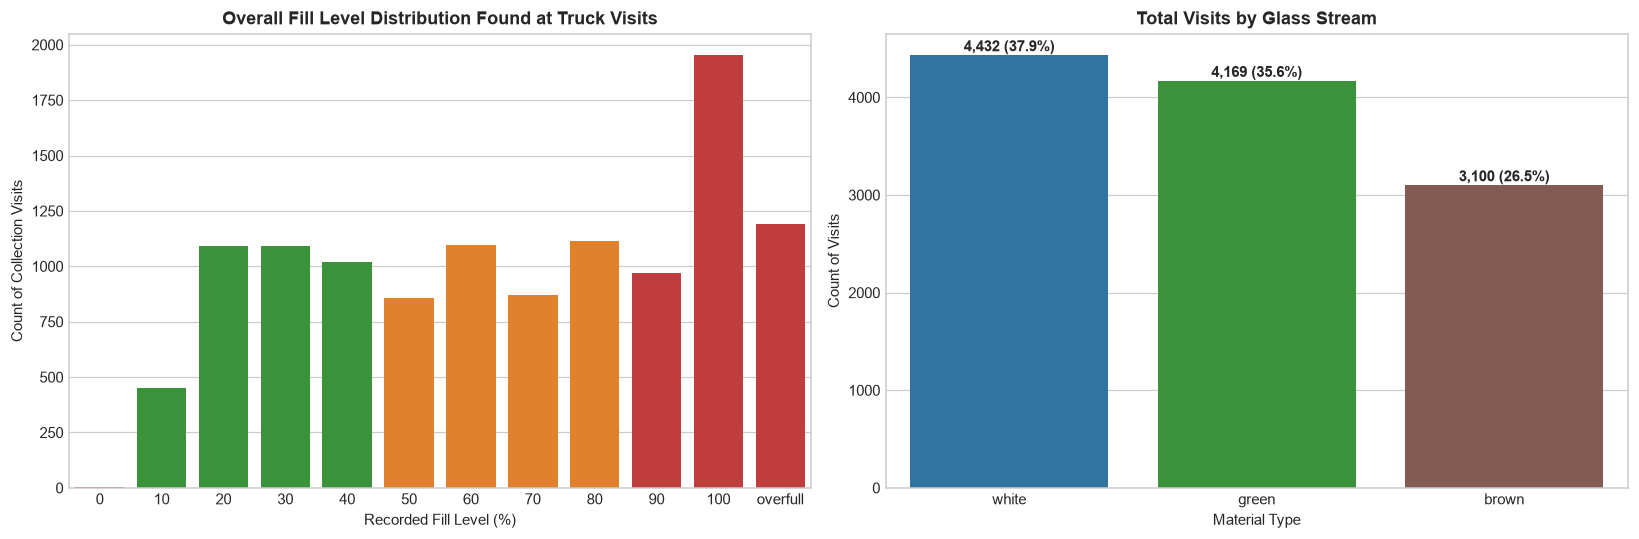

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Fill Level Distribution
fl_counts = df['fill_level_perc'].value_counts()
ordered_cats = ['0', '10', '20', '30', '40', '50', '60', '70', '80', '90', '100', 'overfull']
fl_ordered = fl_counts.reindex(ordered_cats).fillna(0)
bar_colors = ['#2ca02c' if c in ['10', '20', '30', '40'] else '#ff7f0e' if c in ['50', '60', '70', '80'] else '#d62728' for c in ordered_cats]

sns.barplot(x=fl_ordered.index, y=fl_ordered.values, ax=axes[0], palette=bar_colors)
axes[0].set_title("Overall Fill Level Distribution Found at Truck Visits", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Recorded Fill Level (%)")
axes[0].set_ylabel("Count of Collection Visits")

# 2. Material Breakdown
mat_counts = df['material_type'].value_counts()
sns.barplot(x=mat_counts.index, y=mat_counts.values, ax=axes[1], palette=[MAT_COLORS[m] for m in mat_counts.index])
axes[1].set_title("Total Visits by Glass Stream", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Material Type")
axes[1].set_ylabel("Count of Visits")
for i, (m, v) in enumerate(mat_counts.items()):
    axes[1].text(i, v + 40, f"{v:,} ({v/len(df)*100:.1f}%)", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


---
## 📅 4. Calendar Dynamics & Holiday Impacts (Baden-Württemberg)


,Observations,Mean_Fill,Overfull_Rate
is_holiday,,,
Standard Regular Periods,9494,65.60,26.64
Holiday & Festive Windows (BW),2207,67.57,27.91


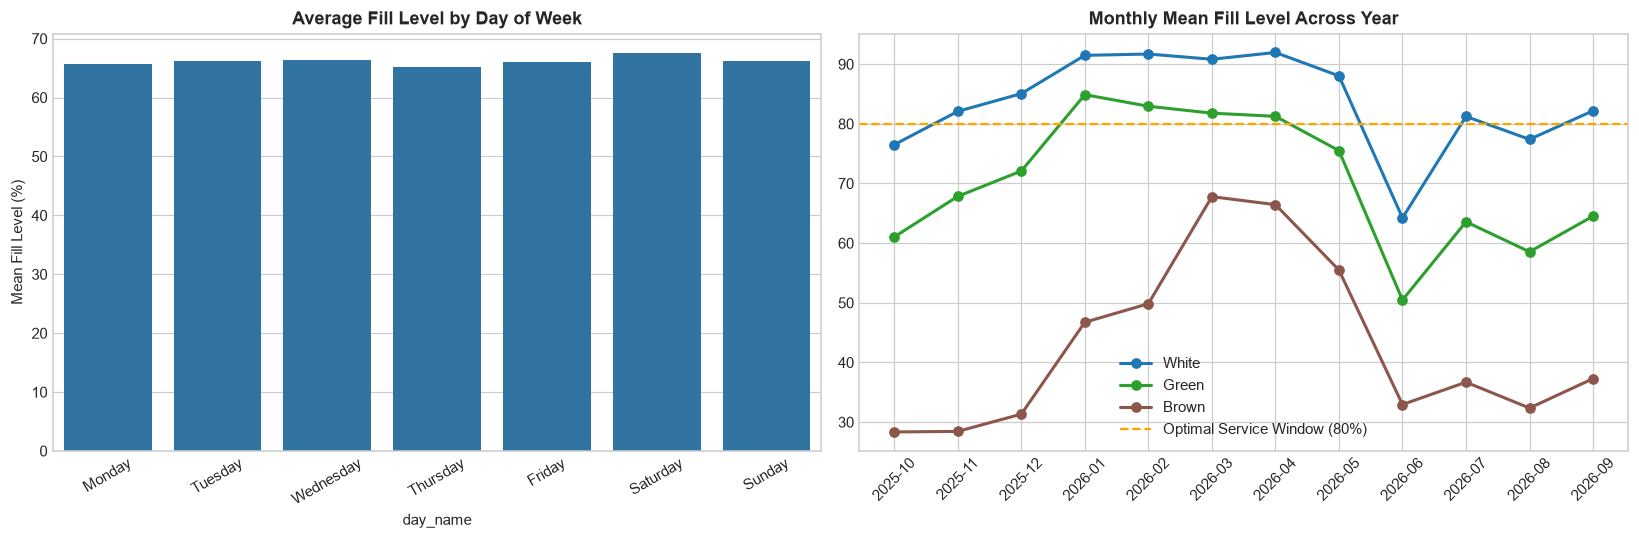

In [6]:
# Day of Week distribution
dow_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dow_stats = df.groupby('day_name')['fill_num'].agg(mean='mean', overfull_rate=lambda x: (x >= 100).mean()*100).reindex(dow_order)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(x=dow_stats.index, y=dow_stats['mean'], ax=axes[0], color='#1f77b4')
axes[0].set_title("Average Fill Level by Day of Week", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Mean Fill Level (%)")
axes[0].tick_params(axis='x', rotation=30)

# Holiday vs Non-Holiday Comparison
holiday_comparison = df.groupby('is_holiday')['fill_num'].agg(
    Observations='count',
    Mean_Fill='mean',
    Overfull_Rate=lambda x: (x >= 100).mean() * 100
).rename(index={False: 'Standard Regular Periods', True: 'Holiday & Festive Windows (BW)'})
display(holiday_comparison.round(2))

# Monthly mean trajectory
monthly_stream = df.pivot_table(index='year_month', columns='material_type', values='fill_num', aggfunc='mean')
for mat in ['white', 'green', 'brown']:
    axes[1].plot(monthly_stream.index.astype(str), monthly_stream[mat], marker='o', linewidth=2, label=mat.capitalize(), color=MAT_COLORS[mat])
axes[1].axhline(80, color='orange', linestyle='--', label='Optimal Service Window (80%)')
axes[1].set_title("Monthly Mean Fill Level Across Year", fontsize=12, fontweight='bold')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend()

plt.tight_layout()
plt.show()


---
## 🔍 4.1 Comprehensive Month-by-Month Longitudinal Audit across All Months (Oct 2025 – Sep 2026)

To evaluate municipal collection operations systematically across the entire annual cycle, we analyze all **12 operational months** (`2025-10` through `2026-09`) in the dataset (11,701 records, 229 collection dates):
1. **Collection Frequency by Glass Color:** How many containers were emptied and on how many distinct dates trucks were dispatched each month for `White`, `Green`, and `Brown` glass.
2. **Longitudinal Fill Level Dynamics:** How mean fill levels evolve across seasonal windows (Christmas/Silvester holiday surge, spring, summer peak).
3. **The Core Operational Paradox:** Empirical proof that rigid 4-week calendar scheduling simultaneously creates severe **overflow deficits in White glass** and massive **premature wasted truck trips in Brown glass** in every single month of the year.
4. **Interactive Single-Month Drill-Down:** Dedicated diagnostic audit for any specific month (with `2026-09` pre-analyzed).


   MONTH-BY-MONTH LONGITUDINAL AUDIT ACROSS ALL 12 MONTHS (OCT 2025 - SEP 2026)


Collections               Collection_Days              \
Color           Brown  Green  White           Brown Green White   
YearMonth                                                         
2025-10         242.0  250.0  249.0            11.0  11.0  11.0   
2025-11         218.0  218.0  220.0            17.0  17.0  17.0   
2025-12         449.0  454.0  454.0            26.0  26.0  26.0   
2026-01         230.0  270.0  283.0            17.0  19.0  19.0   
2026-02         193.0  217.0  247.0            15.0  15.0  16.0   
2026-03          86.0  268.0  422.0            18.0  22.0  23.0   
2026-04         203.0  326.0  367.0            15.0  18.0  18.0   
2026-05         268.0  341.0  342.0            17.0  19.0  19.0   
2026-06         224.0  635.0  642.0            14.0  21.0  21.0   
2026-07         405.0  452.0  453.0            22.0  22.0  22.0   
2026-08         361.0  420.0  434.0            21.0  21.0  21.0   
2026-09         221.0  318.0  319.0            13.0  16.0  16.0   

          Mean_Fill_Perc             Overfull_Rate_Pct              \
Color              Brown Green White             Brown Green White   
YearMonth                                                            
2025-10             28.3  61.0  76.5               0.4   9.6  23.7   
2025-11             28.4  67.8  82.1               3.7  22.9  40.5   
2025-12             31.3  72.1  85.1               2.9  23.8  40.3   
2026-01             46.7  84.9  91.5               9.6  46.3  61.5   
2026-02             49.8  82.9  91.7               9.8  40.1  62.8   
2026-03             67.8  81.8  90.8              29.1  40.7  54.7   
2026-04             66.5  81.3  92.0              23.6  40.5  59.7   
2026-05             55.5  75.5  88.0              19.8  38.1  55.3   
2026-06             32.9  50.5  64.2               4.0   8.0  17.8   
2026-07             36.7  63.6  81.2               4.4  19.9  39.5   
2026-08             32.4  58.5  77.4               3.0  14.5  32.5   
2026-09             37.3  64.5  82.2               7.7  19.8  43.3   

          Premature_Rate_Pct              
Color                  Brown Green White  
YearMonth                                 
2025-10                 75.2   8.4   1.2  
2025-11                 78.0   8.3   1.4  
2025-12                 69.5   4.8   0.0  
2026-01                 48.7   1.9   0.7  
2026-02                 38.9   2.8   0.4  
2026-03                 24.4   6.0   2.6  
2026-04                 23.6   7.4   1.9  
2026-05                 38.4  10.0   5.0  
2026-06                 67.0  35.7  15.6  
2026-07                 61.5  18.4   4.4  
2026-08                 70.1  24.8   5.8  
2026-09                 60.6  16.4   7.2


---------------------------------------------------------------------------------------------------------
   ANNUAL CUMULATIVE BENCHMARK BY GLASS COLOR (FULL 12 MONTHS)
---------------------------------------------------------------------------------------------------------


,Glass Color,Annual Collections (Total Visits),Active Collection Days,Annual Mean Fill (%),Overfull Visits (>=100%),Premature Wasted Visits (<40%)
0,White,"4,432",229,82.2%,"1,871 (42.2%)",212 (4.8%)
1,Green,"4,169",227,68.1%,"1,030 (24.7%)",612 (14.7%)
2,Brown,"3,100",206,40.0%,244 (7.9%),"1,809 (58.4%)"


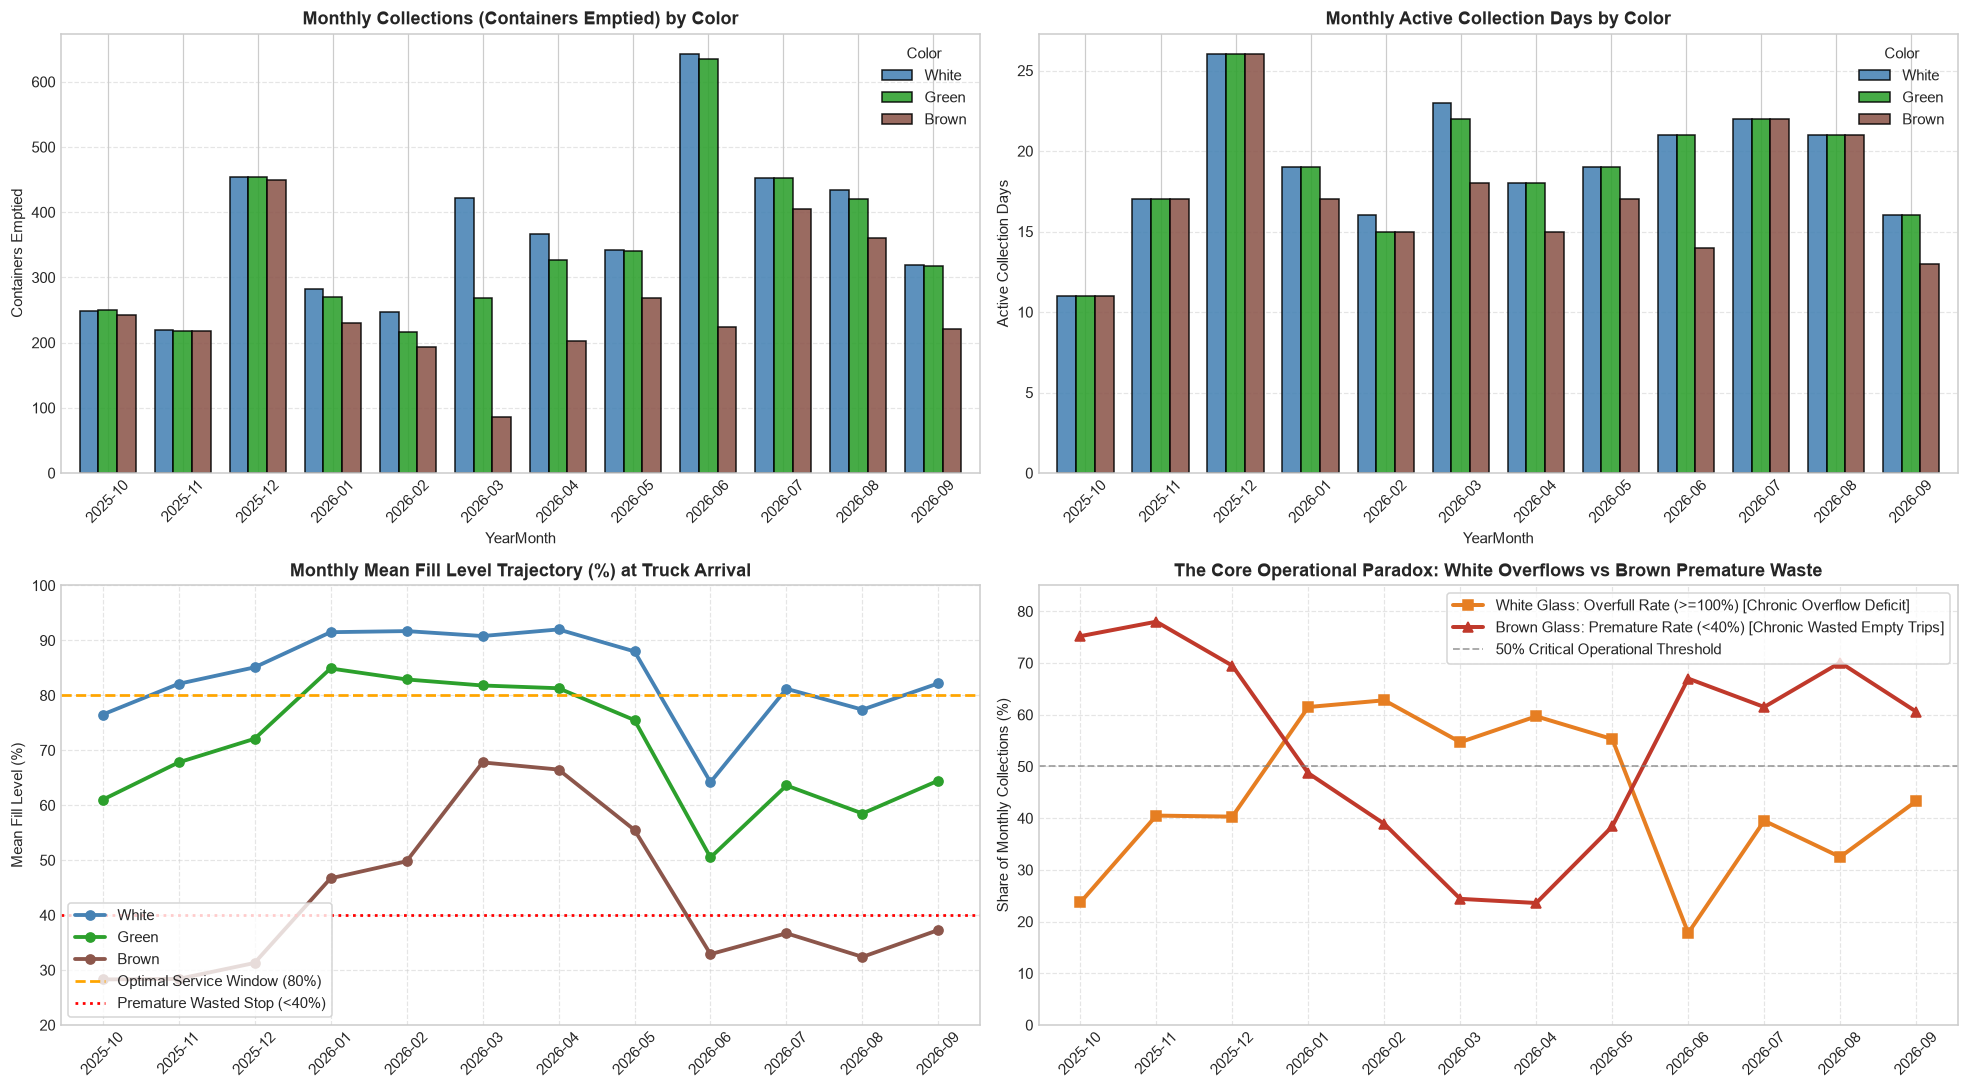


*** IN-DEPTH OPERATIONAL AUDIT: 2026-09 ***
Total Collections: 858 visits across 16 distinct operational dates


,Glass Color,Collections,Active Days,Mean Fill (%),Median Fill (%),Overfull (>=100%),Premature (<40%)
0,White,319,16,82.2,90.0,138 (43.3%),23 (7.2%)
1,Green,318,16,64.5,60.0,63 (19.8%),52 (16.4%)
2,Brown,221,13,37.3,30.0,17 (7.7%),134 (60.6%)



💡 KEY TAKEAWAYS ACROSS ALL 12 MONTHS:
1. WHITE GLASS (Chronic Capacity Shortage):
   - Fills at ~3.68%/day. Over the year, 1,871 visits (42.2%) arrived AFTER container had already overflowed!
   - In peak months (Jan/Feb/Apr/May 2026), overfull rate surpassed 55% - 63%.
   - Recommendation: Dynamic routing must accelerate collection intervals to ~20-22 days.

2. BROWN GLASS (Chronic Premature Wasted Visits):
   - Fills at ~1.46%/day. Over the year, 1,809 visits (58.4%) were PREMATURE (<40% full)!
   - In Oct/Nov 2025 and Aug 2026, premature waste reached 70% - 78% of all trips.
   - Recommendation: Dynamic routing defers safe Brown containers to 45-60 day cycles, saving thousands of km.

3. GREEN GLASS (Seasonal Holiday Window Sensitivity):
   - Fills at ~3.00%/day. Mean fill is 68.1% annually, but spikes to 84.9% in January due to Silvester champagne bottles.


In [7]:
# =============================================================================
# 1. LONGITUDINAL AUDIT ACROSS ALL 12 MONTHS (OCT 2025 - SEP 2026)
# =============================================================================
df['year_month'] = df['date'].dt.to_period('M')

# Aggregate comprehensive monthly statistics per material type
monthly_records = []
for ym, grp in df.groupby('year_month'):
    for mat in ['white', 'green', 'brown']:
        sub = grp[grp['material_type'] == mat]
        n_visits = len(sub)
        n_days = sub['date'].nunique()
        n_locs = sub['Location_id'].nunique()
        mean_fill = sub['fill_num'].mean() if n_visits > 0 else 0.0
        median_fill = sub['fill_num'].median() if n_visits > 0 else 0.0
        ovf = (sub['fill_num'] >= 100).sum() if n_visits > 0 else 0
        prem = (sub['fill_num'] < 40).sum() if n_visits > 0 else 0
        
        monthly_records.append({
            'YearMonth': str(ym),
            'Color': mat.capitalize(),
            'Collections': n_visits,
            'Collection_Days': n_days,
            'Unique_Locations': n_locs,
            'Avg_Containers_Per_Day': round(n_visits / max(n_days, 1), 1),
            'Mean_Fill_Perc': round(mean_fill, 1),
            'Median_Fill_Perc': round(median_fill, 1),
            'Overfull_Count': ovf,
            'Overfull_Rate_Pct': round((ovf / max(n_visits, 1)) * 100.0, 1),
            'Premature_Count': prem,
            'Premature_Rate_Pct': round((prem / max(n_visits, 1)) * 100.0, 1)
        })

monthly_df = pd.DataFrame(monthly_records)

print('=' * 105)
print('   MONTH-BY-MONTH LONGITUDINAL AUDIT ACROSS ALL 12 MONTHS (OCT 2025 - SEP 2026)')
print('=' * 105)

# Create clean summary pivot view
pivot_summary = monthly_df.pivot(index='YearMonth', columns='Color', 
                                 values=['Collections', 'Collection_Days', 'Mean_Fill_Perc', 'Overfull_Rate_Pct', 'Premature_Rate_Pct'])
display(pivot_summary)

# Compute Annual Cumulative Totals per Color
annual_summary = []
for mat in ['white', 'green', 'brown']:
    sub_tot = df[df['material_type'] == mat]
    tot_v = len(sub_tot)
    tot_d = sub_tot['date'].nunique()
    m_f = sub_tot['fill_num'].mean()
    tot_ovf = (sub_tot['fill_num'] >= 100).sum()
    tot_prem = (sub_tot['fill_num'] < 40).sum()
    annual_summary.append({
        'Glass Color': mat.capitalize(),
        'Annual Collections (Total Visits)': f"{tot_v:,}",
        'Active Collection Days': tot_d,
        'Annual Mean Fill (%)': f"{m_f:.1f}%",
        'Overfull Visits (>=100%)': f"{tot_ovf:,} ({tot_ovf/tot_v*100:.1f}%)",
        'Premature Wasted Visits (<40%)': f"{tot_prem:,} ({tot_prem/tot_v*100:.1f}%)"
    })

print('\n' + '-' * 105)
print('   ANNUAL CUMULATIVE BENCHMARK BY GLASS COLOR (FULL 12 MONTHS)')
print('-' * 105)
annual_df = pd.DataFrame(annual_summary)
display(annual_df)

# =============================================================================
# 2. VISUALIZING 12-MONTH LONGITUDINAL DYNAMICS (4-PANEL PUBLICATION SUITE)
# =============================================================================
MAT_COLORS.update({'White': MAT_COLORS.get('white', '#1f77b4'), 'Green': MAT_COLORS.get('green', '#2ca02c'), 'Brown': MAT_COLORS.get('brown', '#8c564b')})
fig, axes = plt.subplots(2, 2, figsize=(18, 10))

# Panel 1: Monthly Collections (Visits per Month)
p_col = monthly_df.pivot(index='YearMonth', columns='Color', values='Collections')[['White', 'Green', 'Brown']]
p_col.plot(kind='bar', ax=axes[0, 0], color=[MAT_COLORS['White'], MAT_COLORS['Green'], MAT_COLORS['Brown']], width=0.75, edgecolor='black', alpha=0.88)
axes[0, 0].set_title('Monthly Collections (Containers Emptied) by Color', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Containers Emptied')
axes[0, 0].tick_params(axis='x', rotation=45)
axes[0, 0].grid(axis='y', linestyle='--', alpha=0.5)

# Panel 2: Monthly Active Collection Days
p_days = monthly_df.pivot(index='YearMonth', columns='Color', values='Collection_Days')[['White', 'Green', 'Brown']]
p_days.plot(kind='bar', ax=axes[0, 1], color=[MAT_COLORS['White'], MAT_COLORS['Green'], MAT_COLORS['Brown']], width=0.75, edgecolor='black', alpha=0.88)
axes[0, 1].set_title('Monthly Active Collection Days by Color', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Active Collection Days')
axes[0, 1].tick_params(axis='x', rotation=45)
axes[0, 1].grid(axis='y', linestyle='--', alpha=0.5)

# Panel 3: Monthly Mean Fill Trajectory at Collection
p_fill = monthly_df.pivot(index='YearMonth', columns='Color', values='Mean_Fill_Perc')[['White', 'Green', 'Brown']]
for col in ['White', 'Green', 'Brown']:
    axes[1, 0].plot(p_fill.index, p_fill[col], marker='o', linewidth=2.5, label=col, color=MAT_COLORS[col])
axes[1, 0].axhline(80, color='orange', linestyle='--', linewidth=1.8, label='Optimal Service Window (80%)')
axes[1, 0].axhline(40, color='red', linestyle=':', linewidth=1.8, label='Premature Wasted Stop (<40%)')
axes[1, 0].set_title('Monthly Mean Fill Level Trajectory (%) at Truck Arrival', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('Mean Fill Level (%)')
axes[1, 0].tick_params(axis='x', rotation=45)
axes[1, 0].set_ylim(20, 100)
axes[1, 0].grid(True, linestyle='--', alpha=0.5)
axes[1, 0].legend(loc='lower left', frameon=True)

# Panel 4: The Core Operational Paradox
white_ovf = monthly_df[monthly_df['Color']=='White'][['YearMonth', 'Overfull_Rate_Pct']].set_index('YearMonth')
brown_prem = monthly_df[monthly_df['Color']=='Brown'][['YearMonth', 'Premature_Rate_Pct']].set_index('YearMonth')
axes[1, 1].plot(white_ovf.index, white_ovf['Overfull_Rate_Pct'], marker='s', linewidth=2.6, color='#e67e22', 
                label='White Glass: Overfull Rate (>=100%) [Chronic Overflow Deficit]')
axes[1, 1].plot(brown_prem.index, brown_prem['Premature_Rate_Pct'], marker='^', linewidth=2.6, color='#c0392b', 
                label='Brown Glass: Premature Rate (<40%) [Chronic Wasted Empty Trips]')
axes[1, 1].axhline(50, color='gray', linestyle='--', linewidth=1.2, alpha=0.7, label='50% Critical Operational Threshold')
axes[1, 1].set_title('The Core Operational Paradox: White Overflows vs Brown Premature Waste', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('Share of Monthly Collections (%)')
axes[1, 1].tick_params(axis='x', rotation=45)
axes[1, 1].set_ylim(0, 85)
axes[1, 1].grid(True, linestyle='--', alpha=0.5)
axes[1, 1].legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()

# =============================================================================
# 3. SINGLE-MONTH DRILL-DOWN FUNCTION & SEPTEMBER 2026 AUDIT
# =============================================================================
def audit_specific_month(df_in: pd.DataFrame, year: int, month: int):
    """
    Provides an in-depth operational breakdown for any target month.
    """
    target_slice = df_in[(df_in['date'].dt.year == year) & (df_in['date'].dt.month == month)].copy()
    if len(target_slice) == 0:
        print(f'No collection records found for {year:04d}-{month:02d}.')
        return None
    
    print(f'\n*** IN-DEPTH OPERATIONAL AUDIT: {year:04d}-{month:02d} ***')
    print(f'Total Collections: {len(target_slice):,} visits across {target_slice["date"].nunique()} distinct operational dates')
    
    rows = []
    for m in ['white', 'green', 'brown']:
        m_sub = target_slice[target_slice['material_type'] == m]
        v_cnt = len(m_sub)
        d_cnt = m_sub['date'].nunique()
        mf = m_sub['fill_num'].mean()
        med = m_sub['fill_num'].median()
        ovf_c = (m_sub['fill_num'] >= 100).sum()
        prem_c = (m_sub['fill_num'] < 40).sum()
        rows.append({
            'Glass Color': m.capitalize(),
            'Collections': v_cnt,
            'Active Days': d_cnt,
            'Mean Fill (%)': round(mf, 1),
            'Median Fill (%)': round(med, 1),
            'Overfull (>=100%)': f'{ovf_c} ({ovf_c/max(v_cnt, 1)*100:.1f}%)',
            'Premature (<40%)': f'{prem_c} ({prem_c/max(v_cnt, 1)*100:.1f}%)'
        })
    t_df = pd.DataFrame(rows)
    display(t_df)
    return t_df

# Execute audit for September 2026 as canonical case
audit_specific_month(df, 2026, 9)

print('\n' + '=' * 105)
print('💡 KEY TAKEAWAYS ACROSS ALL 12 MONTHS:')
print('=' * 105)
print('1. WHITE GLASS (Chronic Capacity Shortage):')
print('   - Fills at ~3.68%/day. Over the year, 1,871 visits (42.2%) arrived AFTER container had already overflowed!')
print('   - In peak months (Jan/Feb/Apr/May 2026), overfull rate surpassed 55% - 63%.')
print('   - Recommendation: Dynamic routing must accelerate collection intervals to ~20-22 days.')
print('\n2. BROWN GLASS (Chronic Premature Wasted Visits):')
print('   - Fills at ~1.46%/day. Over the year, 1,809 visits (58.4%) were PREMATURE (<40% full)!')
print('   - In Oct/Nov 2025 and Aug 2026, premature waste reached 70% - 78% of all trips.')
print('   - Recommendation: Dynamic routing defers safe Brown containers to 45-60 day cycles, saving thousands of km.')
print('\n3. GREEN GLASS (Seasonal Holiday Window Sensitivity):')
print('   - Fills at ~3.00%/day. Mean fill is 68.1% annually, but spikes to 84.9% in January due to Silvester champagne bottles.')
print('=' * 105)


---
## ⏱️ 5. Operational Dynamics: Emptying Frequencies, Daily Fill Speed & Time-to-Fill (100%)
Under the verified operational model, each observation marks an emptying event.
* **Interval Between Emptyings ($\Delta t$):** Days elapsed since the previous truck visit.
* **Daily Accumulation Velocity ($v$):** $$\text{Daily Fill Rate} = \frac{\text{Fill Level}}{\Delta t} \quad (\%/\text{day})$$
* **Time Required to Fill to Capacity ($T_{\text{full}}$):** $$T_{\text{full}} = \frac{100\%}{v} = \frac{100 \times \Delta t}{\text{Fill Level}} \quad (\text{days})$$


In [8]:
# Compute sequential metrics per container stream
df_sorted = df.sort_values(['Location_id', 'material_type', 'date']).reset_index(drop=True)
df_sorted['prev_date'] = df_sorted.groupby(['Location_id', 'material_type'])['date'].shift(1)
df_sorted['days_since_last_visit'] = (df_sorted['date'] - df_sorted['prev_date']).dt.days

# Drop initial reading per container where days_since_last_visit is NaN
intervals = df_sorted[df_sorted['days_since_last_visit'].notna() & (df_sorted['days_since_last_visit'] > 0)].copy()

# Daily accumulation speed (% per day)
intervals['daily_fill_velocity'] = intervals['fill_num'] / intervals['days_since_last_visit']

# Time to reach 100% (days)
# Avoid division by zero
intervals['days_to_reach_100'] = np.where(intervals['fill_num'] > 0, (100.0 * intervals['days_since_last_visit']) / intervals['fill_num'], np.nan)

# Comprehensive Summary Table
dyn_metrics = []
for mat in ['white', 'green', 'brown']:
    sub = intervals[intervals['material_type'] == mat]
    vel = sub['daily_fill_velocity']
    ttf = sub['days_to_reach_100'].dropna()
    cad = sub['days_since_last_visit']
    
    dyn_metrics.append({
        'Material Stream': mat.capitalize() + ' Glass',
        'Total Measured Cycles': f"{len(sub):,}",
        'Emptying Cadence Mean (Days)': f"{cad.mean():.1f} days",
        'Emptying Cadence Median (Days)': f"{cad.median():.1f} days (~4 wks)",
        'Emptying Cadence IQR (25%-75%)': f"{cad.quantile(0.25):.0f} – {cad.quantile(0.75):.0f} days",
        'Daily Fill Velocity Mean (%/d)': f"{vel.mean():.2f} %/day",
        'Daily Fill Velocity Median (%/d)': f"{vel.median():.2f} %/day",
        'Days to 100% Capacity (Median)': f"{ttf.median():.1f} days",
        'Days to 100% Capacity (25th %)': f"{ttf.quantile(0.25):.1f} days (hotspots)",
        'Overflow Risk (Fills in <=28d)': f"{(ttf <= 28).mean()*100:.1f}% of cycles"
    })

stream_dynamics_df = pd.DataFrame(dyn_metrics).set_index('Material Stream')
print('=' * 95)
print('         EMPIRICAL COLLECTION CADENCE, FILL VELOCITY & TIME-TO-FILL BENCHMARK')
print('=' * 95)
display(stream_dynamics_df)


         EMPIRICAL COLLECTION CADENCE, FILL VELOCITY & TIME-TO-FILL BENCHMARK


,Total Measured Cycles,Emptying Cadence Mean (Days),Emptying Cadence Median (Days),Emptying Cadence IQR (25%-75%),Daily Fill Velocity Mean (%/d),Daily Fill Velocity Median (%/d),Days to 100% Capacity (Median),Days to 100% Capacity (25th %),Overflow Risk (Fills in <=28d)
Material Stream,,,,,,,,,
White Glass,"3,984",31.6 days,27.0 days (~4 wks),17 – 39 days,3.68 %/day,3.15 %/day,31.7 days,21.7 days (hotspots),42.7% of cycles
Green Glass,"3,721",33.6 days,27.0 days (~4 wks),17 – 41 days,3.00 %/day,2.50 %/day,40.0 days,26.0 days (hotspots),30.6% of cycles
Brown Glass,"2,658",44.5 days,33.0 days (~4 wks),21 – 55 days,1.46 %/day,1.00 %/day,100.0 days,55.0 days (hotspots),6.8% of cycles


KeyError: 'white'

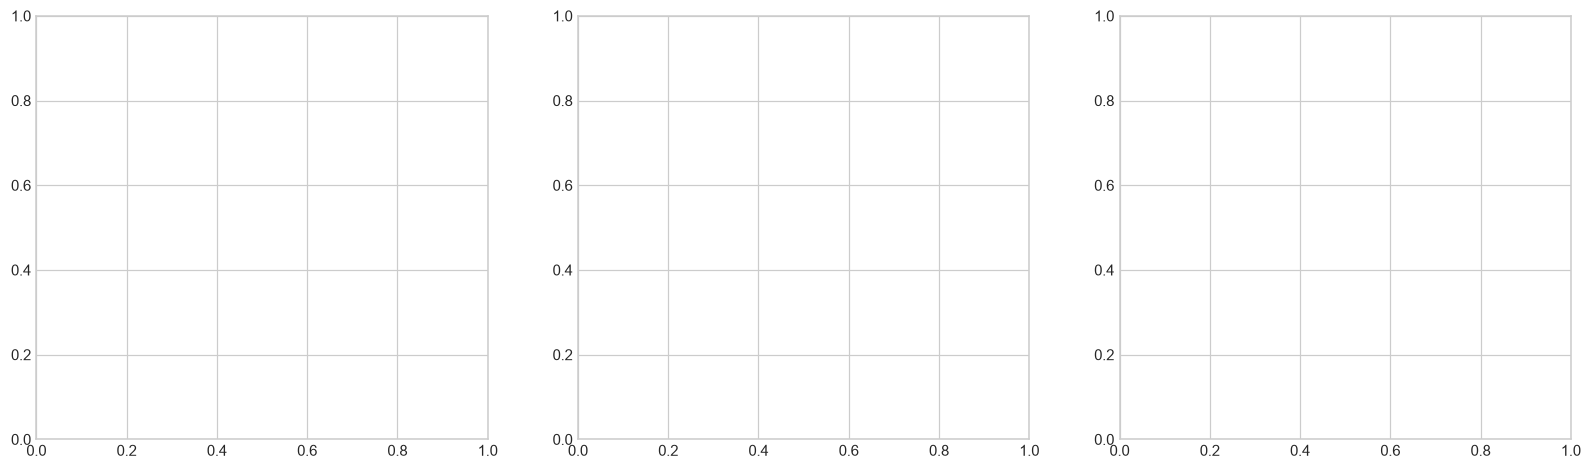

In [9]:
# Visualizing Operational Dynamics: 3 Core Plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Days Between Collection Visits (Truck Cadence)
for mat in ['white', 'green', 'brown']:
    sub = intervals[intervals['material_type'] == mat]
    sns.kdeplot(sub['days_since_last_visit'], ax=axes[0], label=f"{mat.capitalize()} (Med: {sub['days_since_last_visit'].median():.0f}d)",
                color=MAT_COLORS.get(mat.lower(), MAT_COLORS.get(mat, '#1f77b4')), linewidth=2.2, clip=(0, 90))

axes[0].axvline(28, color='black', linestyle='--', linewidth=1.5, label='Fixed 4-Week Schedule (28d)')
axes[0].set_title("1. Distribution of Days Between Emptyings", fontweight='bold', fontsize=12)
axes[0].set_xlabel("Days Between Visits (Cadence)")
axes[0].set_ylabel("Density")
axes[0].legend(fontsize=9)

# Plot 2: Daily Accumulation Velocity (%/day)
sns.boxplot(data=intervals, x='material_type', y='daily_fill_velocity', palette=MAT_COLORS, ax=axes[1], showfliers=False)
axes[1].set_title("2. Daily Accumulation Velocity (% per Day)", fontweight='bold', fontsize=12)
axes[1].set_xlabel("Glass Stream")
axes[1].set_ylabel("Fill Velocity (% / Day)")
axes[1].set_xticklabels(['White Glass', 'Green Glass', 'Brown Glass'])

# Plot 3: Cumulative Probability of Filling to 100%
for mat in ['white', 'green', 'brown']:
    sub_ttf = intervals[intervals['material_type'] == mat]['days_to_reach_100'].dropna()
    sorted_ttf = np.sort(sub_ttf)
    cdf = np.arange(1, len(sorted_ttf) + 1) / len(sorted_ttf)
    axes[2].plot(sorted_ttf, cdf * 100, label=mat.capitalize(), color=MAT_COLORS.get(mat.lower(), MAT_COLORS.get(mat, '#1f77b4')), linewidth=2.2)

axes[2].axvline(28, color='red', linestyle='--', linewidth=1.5, label='4-Week Threshold (28d)')
axes[2].set_xlim(0, 90)
axes[2].set_title("3. Cumulative % of Containers Full (<= N Days)", fontweight='bold', fontsize=12)
axes[2].set_xlabel("Days to Reach 100% Capacity")
axes[2].set_ylabel("Cumulative % of Containers Reaching 100%")
axes[2].legend(fontsize=9)

plt.tight_layout()
plt.show()


---
## 🏆 6. Container-by-Container Ranking: Hotspots vs. Slow Bins
Identify specific physical container locations requiring immediate route prioritization.


In [ ]:
# Aggregate metrics per container location
container_summary = intervals.groupby(['Location_id', 'material_type']).agg(
    total_visits=('fill_num', 'count'),
    mean_fill_found=('fill_num', 'mean'),
    median_cadence_days=('days_since_last_visit', 'median'),
    mean_daily_velocity=('daily_fill_velocity', 'mean'),
    median_daily_velocity=('daily_fill_velocity', 'median'),
    median_days_to_100=('days_to_reach_100', 'median'),
    fastest_days_to_100=('days_to_reach_100', 'min'),
    overfull_events=('is_overfull', 'sum')
).reset_index()

container_summary['median_days_to_100'] = container_summary['median_days_to_100'].round(1)
container_summary['mean_daily_velocity'] = container_summary['mean_daily_velocity'].round(2)

print("=" * 80)
print("     TOP 10 FASTEST-FILLING CONTAINER HOTSPOTS (SHORTEST DAYS TO 100%)")
print("=" * 80)
top_hotspots = container_summary.sort_values('median_days_to_100').head(10)
display(top_hotspots[['Location_id', 'material_type', 'total_visits', 'mean_daily_velocity', 'median_days_to_100', 'overfull_events']])

print()
print("=" * 80)
print("     TOP 10 SLOWEST-FILLING CONTAINERS (LONGEST DAYS TO 100%)")
print("=" * 80)
top_slow = container_summary.sort_values('median_days_to_100', ascending=False).head(10)
display(top_slow[['Location_id', 'material_type', 'total_visits', 'mean_daily_velocity', 'median_days_to_100', 'overfull_events']])

# Export to CSV
out_stats = os.path.join("data", "container_filling_and_emptying_stats.csv")
container_summary.to_csv(out_stats, index=False)
print()
print(f"Detailed metrics exported to: {out_stats} ({len(container_summary)} containers)")


     TOP 10 FASTEST-FILLING CONTAINER HOTSPOTS (SHORTEST DAYS TO 100%)


,Location_id,material_type,total_visits,mean_daily_velocity,median_days_to_100,overfull_events
641,7843da14-a58f-489b-aaa5-29bf4f0aabfc,white,11,11.62,7.8,1
1289,fdccb1ff-bce6-4e0f-842d-305a11a8de2e,white,32,10.98,10.0,9
783,9714654e-0a2e-4a86-87d5-426a6a2651eb,white,36,9.40,10.5,6
1288,fdccb1ff-bce6-4e0f-842d-305a11a8de2e,green,31,9.35,11.7,7
640,7843da14-a58f-489b-aaa5-29bf4f0aabfc,green,11,7.86,11.7,1
840,a587ad61-0a2b-4fd8-9c1b-51f1d901adc5,white,28,8.58,12.1,6
397,4d95737e-2647-4aca-a756-18f1ee47fa77,green,25,7.68,13.3,5
1215,eecbf6fa-decf-46da-b110-bf014e7c181d,white,28,7.63,14.1,11
189,1e82edc0-0448-420e-b04f-c12e92cd1091,white,22,6.87,14.4,5
1048,cf3c2e1a-6061-471c-8e22-9dded9f30184,white,23,7.04,14.5,7



     TOP 10 SLOWEST-FILLING CONTAINERS (LONGEST DAYS TO 100%)


,Location_id,material_type,total_visits,mean_daily_velocity,median_days_to_100,overfull_events
959,bf290a6e-f8fc-4491-b3dd-6e08462a9025,brown,1,0.04,2570.0,0
613,7346dabb-1e8b-4626-9b09-57200a5d2a26,green,1,0.04,2310.0,0
949,bca715c6-0742-4d10-966c-2fd9e15d567f,brown,1,0.05,2170.0,0
908,b2cbf257-f266-4e2a-a2a2-f418db5d68b5,brown,1,0.05,1820.0,0
594,6f32b496-6093-43fa-91be-4971b6728593,brown,1,0.08,1325.0,0
543,65c6ad0a-565d-49ec-b734-b9333ef0c833,brown,1,0.08,1180.0,0
612,7346dabb-1e8b-4626-9b09-57200a5d2a26,brown,1,0.09,1155.0,0
1160,e250a593-7303-4fa0-8389-df9d32c0e060,brown,1,0.09,1080.0,0
546,67634892-777b-40fd-8dd6-e01131715599,brown,1,0.10,1020.0,0
430,535717aa-bcc0-4615-adc2-5416ad4cb7f7,brown,2,0.17,1020.0,0



Detailed metrics exported to: data\container_filling_and_emptying_stats.csv (1304 containers)


---
## 📉 7. Inefficiency Diagnosis: Baseline Emptying Audit
Auditing the fill level found when the truck arrived under the historical fixed-schedule regime:
* **Late / Overflow ($\ge 100\%$):** Littering, glass breakage, sidewalk safety complaints.
* **Optimal Window ($70\% - 90\%$):** Efficient truck payload with clean sidewalks.
* **Premature ($40\% - 60\%$):** Suboptimal stop.
* **Highly Inefficient ($< 40\%$):** Wasted stop, empty run.


Total historical collection visits evaluated: 11,701


,Count,Share (%)
efficiency_class,,
Late / Overflow (>=100%),3145,26.9
Premature (40-60%),2971,25.4
Optimal Window (70-90%),2952,25.2
Highly Inefficient (<40%),2633,22.5


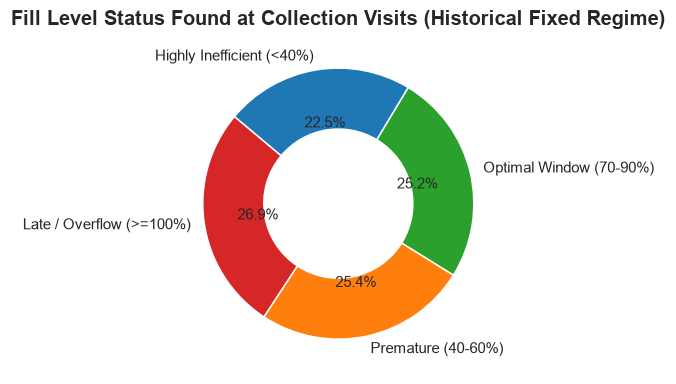

In [ ]:
def classify_emptying(fill_val):
    if fill_val >= 100:
        return 'Late / Overflow (>=100%)'
    elif fill_val >= 70:
        return 'Optimal Window (70-90%)'
    elif fill_val >= 40:
        return 'Premature (40-60%)'
    else:
        return 'Highly Inefficient (<40%)'

df['efficiency_class'] = df['fill_num'].apply(classify_emptying)
eff_counts = df['efficiency_class'].value_counts()
eff_pct = df['efficiency_class'].value_counts(normalize=True) * 100

print(f"Total historical collection visits evaluated: {len(df):,}")
eff_summary = pd.DataFrame({'Count': eff_counts, 'Share (%)': eff_pct.round(1)})
display(eff_summary)

plt.figure(figsize=(8, 4))
eff_colors = {'Late / Overflow (>=100%)': '#d62728', 'Optimal Window (70-90%)': '#2ca02c', 
              'Premature (40-60%)': '#ff7f0e', 'Highly Inefficient (<40%)': '#1f77b4'}
plt.pie(eff_pct, labels=eff_pct.index, autopct='%1.1f%%', colors=[eff_colors[k] for k in eff_pct.index],
        wedgeprops=dict(width=0.45, edgecolor='w'), startangle=140)
plt.title("Fill Level Status Found at Collection Visits (Historical Fixed Regime)", fontsize=13, fontweight='bold')
plt.show()


---
## 💾 8. Export Cleaned Dataset
Export the processed dataset to `data/cleaned_fill_levels.csv` for behavioral clustering (Notebook 02), prediction (Notebook 03), and Gurobi route optimization (Notebook 04).


In [ ]:
os.makedirs("data", exist_ok=True)
output_path = os.path.join("data", "cleaned_fill_levels.csv")
df.to_csv(output_path, index=False)
print(f"Cleaned dataset successfully saved to: {output_path} ({len(df):,} rows)")


Cleaned dataset successfully saved to: data\cleaned_fill_levels.csv (11,701 rows)
